In [1]:
import matplotlib.pyplot as plt
import numpy as np
from utils import *
from scipy.signal import periodogram

# Input PSD

c:\Users\olin_\Documents\Projects\BAUSCIA\SimBa\emulators\utils.py:60: RuntimeWarning: divide by zero encountered in divide
  S = (4 * kB * T * chi(omega0, T) * R / (ZS**2)) * ((tau_inv * omega)**2 / denom)
c:\Users\olin_\Documents\Projects\BAUSCIA\SimBa\emulators\utils.py:60: RuntimeWarning: invalid value encountered in multiply
  S = (4 * kB * T * chi(omega0, T) * R / (ZS**2)) * ((tau_inv * omega)**2 / denom)


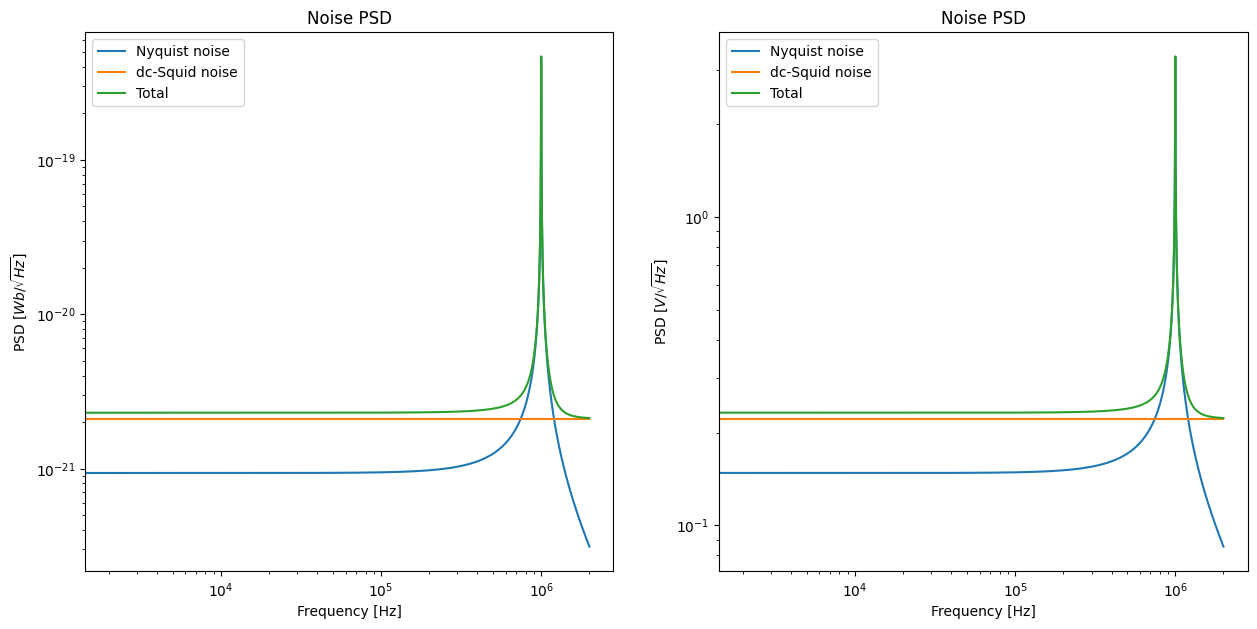

In [2]:

# Example parameters (adjust these as appropriate for your system)
T = 20e-3             # Temperature: 20 mK
R = 5.0               # Motional resistance [Ohm]
Q = 1e9               # Quality factor
f0 = 1e6              # Resonance frequency [Hz] (e.g., 1 MHz)
omega0 = 2 * np.pi * f0  # Resonance angular frequency [rad/s]
LS = 400e-9           # SQUID input inductance [H] (400 nH)
kappa = 1e-2          # Electromechanical coupling coefficient (√(κ²) ~ √(1e-4))

# Additional parameters for backaction and additive noise:
S_i = 1e-24         # SQUID current noise PSD (A^2/Hz); example value
m_eff = 0.1e-3        # Effective mass of the mechanical mode (kg) ~ 1 gram
S_phi_add = 2.1e-21**2 # SQUID additive flux noise PSD (Wb^2/Hz)

# SQUID flux-to-voltage conversion factor, for example:
# If the SQUID provides ~10 µV per flux quantum, then:
V_phi = 10e-6 / phi0  # [V/Wb]

# Define a frequency range (in Hz) around the resonance and convert to angular frequency (rad/s)
freqs = np.linspace(0.e6, 2e6, 1000)  # Frequency from 0.1 MHz to 2 MHz
omega = 2 * np.pi * freqs

# Calculate each noise contribution as a function of frequency
S_phi_nyq = noise_flux_nyq(omega, T, R, Q, omega0, LS)
# S_phi_BA = noise_flux_backaction(omega, omega0, LS, kappa, R, S_i, m_eff, Q)
# For plotting, the additive noise is flat (frequency independent)
S_phi_add_arr = S_phi_add * np.ones_like(omega)


S_phi_tot = noise_flux_total(2*np.pi*freqs, T, R, Q, omega0, LS, kappa, S_i, m_eff, S_phi_add)

fig, ax = plt.subplots(1,2, figsize=(15,7))
ax[0].plot(freqs, np.sqrt(S_phi_nyq), label='Nyquist noise')
# ax[0].plot(freqs, np.sqrt(S_phi_BA), label='Backaction noise')
ax[0].plot(freqs, np.sqrt(S_phi_add_arr), label='dc-Squid noise')
ax[0].plot(freqs, np.sqrt(S_phi_tot), label='Total')
ax[0].set_xlabel("Frequency [Hz]")
ax[0].set_ylabel("PSD [$Wb/\\sqrt{Hz}$]")
ax[0].set_title("Noise PSD")
ax[0].set_xscale('log')
ax[0].set_yscale('log')
ax[0].legend()


ax[1].plot(freqs, flux2voltage_noise(np.sqrt(S_phi_nyq), V_phi), label='Nyquist noise')
# ax[1].plot(freqs, flux2voltage_noise(np.sqrt(S_phi_BA), V_phi), label='Backaction noise')
ax[1].plot(freqs, flux2voltage_noise(np.sqrt(S_phi_add_arr), V_phi), label='dc-Squid noise')
ax[1].plot(freqs, flux2voltage_noise(np.sqrt(S_phi_tot), V_phi), label='Total')
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("PSD [$V/\\sqrt{Hz}$]")
ax[1].set_title("Noise PSD")
ax[1].set_xscale('log')
ax[1].set_yscale('log')
ax[1].legend()


# Generate noise trace

Text(0.5, 1.0, 'Noise time series')

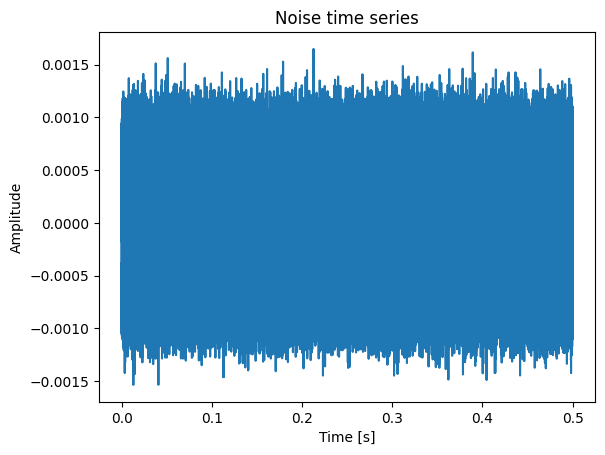

In [3]:
fs = 10e6 # 1 MHz sampling  
Tduration = 500e-3 # 500 milliseconds long time trace

psd = lambda f: flux2voltage_noise(np.sqrt(noise_flux_total(2*np.pi*f, T, R, Q, omega0, LS, kappa, S_i, m_eff, S_phi_add)), V_phi)

t, noise, freqs = generate_noise_vectorized(psd, Tduration, fs, seed=42)
fig, ax = plt.subplots()
ax.plot(t, noise)
ax.set_xlabel("Time [s]")
ax.set_ylabel("Amplitude")
ax.set_title("Noise time series")

# Add signal

Text(0.5, 1.0, 'Signal + Noise time series')

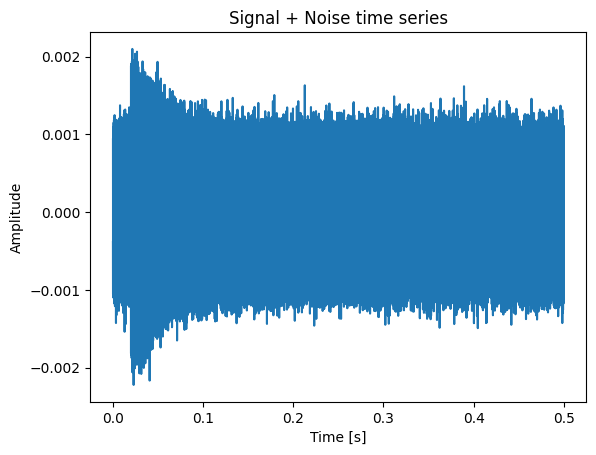

In [4]:
f_signal = f0
t0 = 20e-3
signal = 1e-3*np.sin(2*np.pi*f_signal*t + 0)*(np.heaviside(t-t0, 1)*np.exp(-(t - t0)/50e-3))
x = add_noise_to_signal(signal, noise)
fig, ax = plt.subplots()
ax.plot(t, x)
ax.set_xlabel("Time [s]")
ax.set_ylabel("Amplitude")
ax.set_title("Signal + Noise time series")


In [5]:
def estimate_psd(x, fs):
    freqs, Pxx = periodogram(x,fs, scaling='density')
    return freqs, Pxx

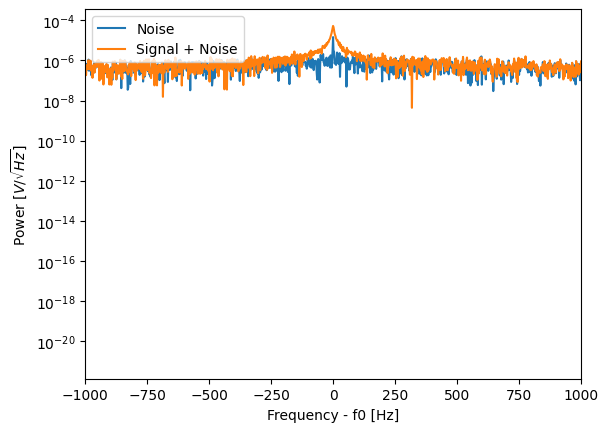

In [6]:
# Parameters


freqs, psd_noise = estimate_psd(noise, fs)
freqs, psd_signal = estimate_psd(x, fs)

fig, ax = plt.subplots()

ax.plot(freqs - f0, np.sqrt(psd_noise), label='Noise')
ax.plot(freqs - f0, np.sqrt(psd_signal), label='Signal + Noise')
ax.set_xlabel("Frequency - f0 [Hz]")
ax.set_ylabel("Power [$V/\\sqrt{Hz}$]")
ax.set_yscale('log')
ax.set_xlim(-1e3, +1e3)


ax.legend(loc='upper left')


# Homodyne detection

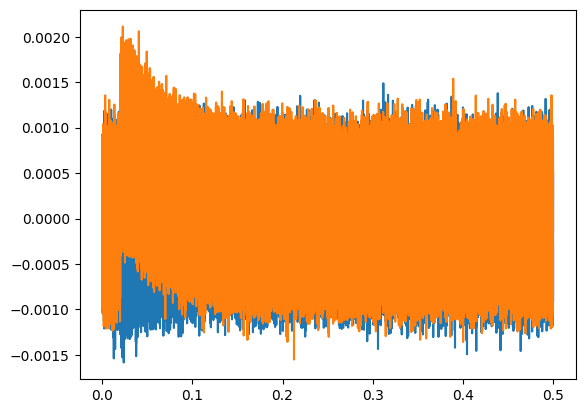

In [7]:


I = x * np.cos(2*np.pi*f0*t)
Q = x * np.sin(2*np.pi*f0*t)

fig,ax = plt.subplots()
ax.plot(t, I)
ax.plot(t, Q)
